# 1. Data Cleaning and EDA - Planetary Defense Analytics

## Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.float_format', '{:,.5f}'.format)

os.makedirs('images', exist_ok=True)

Load the tools we need: pandas for tables, numpy for maths, matplotlib/seaborn for charts; the images folder stores the charts. Numbers are shown as normal values (like 3,810,113.98854) instead of scientific notation (3.810114e+06).

## Read the data

In [2]:
data = pd.read_csv('pha_dataset.csv', low_memory=False)
data.head()

,id,spkid,full_name,pdes,name,prefix,neo,pha,H,diameter,...,sigma_i,sigma_om,sigma_w,sigma_ma,sigma_ad,sigma_n,sigma_tp,sigma_per,class,rms
0,a0000001,2000001,1 Ceres,1,Ceres,NaN,N,N,3.40000,939.40000,...,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,MBA,0.43301
1,a0000002,2000002,2 Pallas,2,Pallas,NaN,N,N,4.20000,545.00000,...,0.00000,0.00001,0.00001,0.00001,0.00000,0.00000,0.00004,0.00000,MBA,0.35936
2,a0000003,2000003,3 Juno,3,Juno,NaN,N,N,5.33000,246.59600,...,0.00000,0.00002,0.00002,0.00001,0.00000,0.00000,0.00004,0.00000,MBA,0.33848
3,a0000004,2000004,4 Vesta,4,Vesta,NaN,N,N,3.00000,525.40000,...,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,MBA,0.39980
4,a0000005,2000005,5 Astraea,5,Astraea,NaN,N,N,6.90000,106.69900,...,0.00000,0.00003,0.00003,0.00001,0.00000,0.00000,0.00003,0.00000,MBA,0.52191


Read the NASA asteroid file into a table so we can work with it, and look at the first 5 rows.

## Shape of the data

In [3]:
data.shape

(958524, 45)

Know how big the data is (rows = asteroids, columns = properties) before deciding anything.

## Column info

In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 958524 entries, 0 to 958523
Data columns (total 45 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   id              958524 non-null  str    
 1   spkid           958524 non-null  int64  
 2   full_name       958524 non-null  str    
 3   pdes            958524 non-null  str    
 4   name            22064 non-null   str    
 5   prefix          18 non-null      str    
 6   neo             958520 non-null  str    
 7   pha             938603 non-null  str    
 8   H               952261 non-null  float64
 9   diameter        136209 non-null  float64
 10  albedo          135103 non-null  float64
 11  diameter_sigma  136081 non-null  float64
 12  orbit_id        958524 non-null  str    
 13  epoch           958524 non-null  float64
 14  epoch_mjd       958524 non-null  int64  
 15  epoch_cal       958524 non-null  float64
 16  equinox         958524 non-null  str    
 17  e               95852

See each column's data type and how many values are filled, to spot text columns and empty columns.

## Summary statistics

In [5]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
spkid,"958,524.00000","3,810,113.98863","6,831,540.88049","2,000,001.00000","2,239,631.75000","2,479,262.50000","3,752,517.75000","54,017,232.00000"
H,"952,261.00000",16.90641,1.79041,-1.10000,16.10000,16.90000,17.71400,33.20000
diameter,"136,209.00000",5.50643,9.42516,0.00250,2.78000,3.97200,5.76500,939.40000
albedo,"135,103.00000",0.13063,0.11032,0.00100,0.05300,0.07900,0.19000,1.00000
diameter_sigma,"136,081.00000",0.47918,0.78290,0.00050,0.18000,0.33200,0.62000,140.00000
epoch,"958,524.00000","2,458,869.28195",701.67157,"2,425,051.50000","2,459,000.50000","2,459,000.50000","2,459,000.50000","2,459,000.50000"
epoch_mjd,"958,524.00000","58,868.78195",701.67157,"25,051.00000","59,000.00000","59,000.00000","59,000.00000","59,000.00000"
epoch_cal,"958,524.00000","20,196,925.05158","19,303.53684","19,270,620.00000","20,200,531.00000","20,200,531.00000","20,200,531.00000","20,200,531.00000"
e,"958,524.00000",0.15612,0.09264,0.00000,0.09219,0.14500,0.20065,1.85536
a,"958,524.00000",2.90214,39.71950,"-14,702.44787",2.38784,2.64697,3.00193,"33,488.89595"


See min, max and average of every number, to catch impossible values (like negative a) and huge ranges.

## Missing values in each column

In [6]:
missing = data.isnull().sum()
missing_percent = (missing / len(data)) * 100
missing_df = pd.DataFrame({'missing': missing, 'percent': missing_percent.round(2)})
missing_df.sort_values('percent', ascending=False)

,missing,percent
prefix,958506,100.00000
name,936460,97.70000
albedo,823421,85.91000
diameter_sigma,822443,85.80000
diameter,822315,85.79000
pha,19921,2.08000
sigma_per,19926,2.08000
sigma_ad,19926,2.08000
sigma_n,19922,2.08000
sigma_i,19922,2.08000


Find how much of each column is empty, to decide whether to drop the column, drop rows or keep it.

## Duplicate rows

In [7]:
data.duplicated().sum()

np.int64(0)

Duplicate rows would be counted twice and bias the model, so we check for them.

## Unique values in each column

In [8]:
data.nunique().sort_values()

prefix                 1
equinox                1
pha                    2
neo                    2
class                 13
albedo              1057
diameter_sigma      3054
orbit_id            4690
epoch_cal           5246
epoch_mjd           5246
epoch               5246
H                   9489
diameter           16591
name               22064
rms                64386
sigma_i           215741
sigma_om          223155
sigma_q           248138
sigma_n           251750
sigma_e           254740
sigma_w           262719
sigma_ma          266816
sigma_ad          269241
sigma_a           273297
sigma_per         282687
sigma_tp          291246
moid              314300
moid_ld           314301
i                 958414
e                 958444
tp_cal            958499
ad                958505
a                 958509
q                 958509
per               958510
per_y             958511
n                 958514
om                958518
w                 958519
ma                958519


Columns with 1 unique value give no information, and columns with all-unique values are IDs; both should be dropped.

## Check the label columns

In [9]:
print(data['pha'].value_counts(dropna=False))
print()
print(data['neo'].value_counts(dropna=False))
print()
print(data['class'].value_counts())

pha
N      936537
NaN     19921
Y        2066
Name: count, dtype: int64

neo
N      935625
Y       22895
NaN         4
Name: count, dtype: int64

class
MBA    855954
OMB     28355
IMB     20360
MCA     18685
APO     12687
AMO      8457
TJN      8221
TNO      3468
ATE      1729
CEN       506
AST        76
IEO        22
HYA         4
Name: count, dtype: int64


Check how many PHAs, NEOs and each orbital class exist, because a rare target changes how we train and judge models.

## Drop identifier, date and error (sigma) columns

In [10]:
drop_cols = ['id', 'spkid', 'full_name', 'pdes', 'name', 'prefix', 'orbit_id',
             'equinox', 'epoch', 'epoch_mjd', 'epoch_cal', 'tp', 'tp_cal',
             'diameter_sigma', 'rms',
             'sigma_e', 'sigma_a', 'sigma_q', 'sigma_i', 'sigma_om', 'sigma_w',
             'sigma_ma', 'sigma_ad', 'sigma_n', 'sigma_tp', 'sigma_per']

data = data.drop(columns=drop_cols)
data.shape

(958524, 19)

Remove IDs, dates and measurement-error columns because they describe the record, not the asteroid, and would confuse the model.

In [11]:
data.columns

Index(['neo', 'pha', 'H', 'diameter', 'albedo', 'e', 'a', 'q', 'i', 'om', 'w',
       'ma', 'ad', 'n', 'per', 'per_y', 'moid', 'moid_ld', 'class'],
      dtype='str')

Confirm which 19 columns are left after dropping.

## Drop rows where pha or neo is missing

In [12]:
data = data.dropna(subset=['pha', 'neo'])
data.shape

(938599, 19)

Rows with no pha answer cannot be used to train or test the classifier, so they are removed.

## Missing values after dropping

In [13]:
data.isnull().sum()

neo              0
pha              0
H             6262
diameter    802390
albedo      803496
e                0
a                0
q                0
i                0
om               0
w                0
ma               1
ad               0
n                0
per              0
per_y            0
moid             0
moid_ld          0
class            0
dtype: int64

Check what is still missing after removing rows with no label.

## Drop rows with missing H, ma, ad, per, per_y, moid_ld (very few rows)

In [14]:
data = data.dropna(subset=['H', 'ma', 'ad', 'per', 'per_y', 'moid_ld'])
data.shape

(932336, 19)

These columns are missing in only a few rows, so dropping those rows is safer than guessing values.

## Check for impossible values

In [15]:
print('e < 0 or e >= 1 :', len(data[(data['e'] < 0) | (data['e'] >= 1)]))
print('a <= 0          :', len(data[data['a'] <= 0]))
print('q <= 0          :', len(data[data['q'] <= 0]))
print('i < 0 or i > 180:', len(data[(data['i'] < 0) | (data['i'] > 180)]))
print('diameter <= 0   :', len(data[data['diameter'] <= 0]))
print('albedo <= 0 or > 1:', len(data[(data['albedo'] <= 0) | (data['albedo'] > 1)]))
print('moid < 0        :', len(data[data['moid'] < 0]))

e < 0 or e >= 1 : 0
a <= 0          : 0
q <= 0          : 0
i < 0 or i > 180: 0
diameter <= 0   : 0
albedo <= 0 or > 1: 0
moid < 0        : 0


Count rows that break physics rules (e >= 1, negative distance, albedo > 1) before removing them.

## Keep only valid rows (diameter and albedo can stay empty)

In [16]:
data = data[(data['e'] >= 0) & (data['e'] < 1)]
data = data[data['a'] > 0]
data = data[data['q'] > 0]
data = data[(data['i'] >= 0) & (data['i'] <= 180)]
data = data[(data['diameter'] > 0) | (data['diameter'].isnull())]
data = data[((data['albedo'] > 0) & (data['albedo'] <= 1)) | (data['albedo'].isnull())]
data = data[data['moid'] >= 0]
data.shape

(932336, 19)

Keep only physically possible asteroids; empty diameter/albedo are allowed because only Case 2 needs them.

## Remove duplicates

In [17]:
data = data.drop_duplicates()
data = data.reset_index(drop=True)
data.shape

(932336, 19)

Remove any duplicate rows and renumber the rows from 0 after all the filtering.

## Missing values left (diameter and albedo only)

In [18]:
data.isnull().sum()

neo              0
pha              0
H                0
diameter    800291
albedo      801096
e                0
a                0
q                0
i                0
om               0
w                0
ma               0
ad               0
n                0
per              0
per_y            0
moid             0
moid_ld          0
class            0
dtype: int64

Confirm that only diameter and albedo still have empty values (expected, 86% unknown).

# EDA

## Univariate - histograms of numeric columns

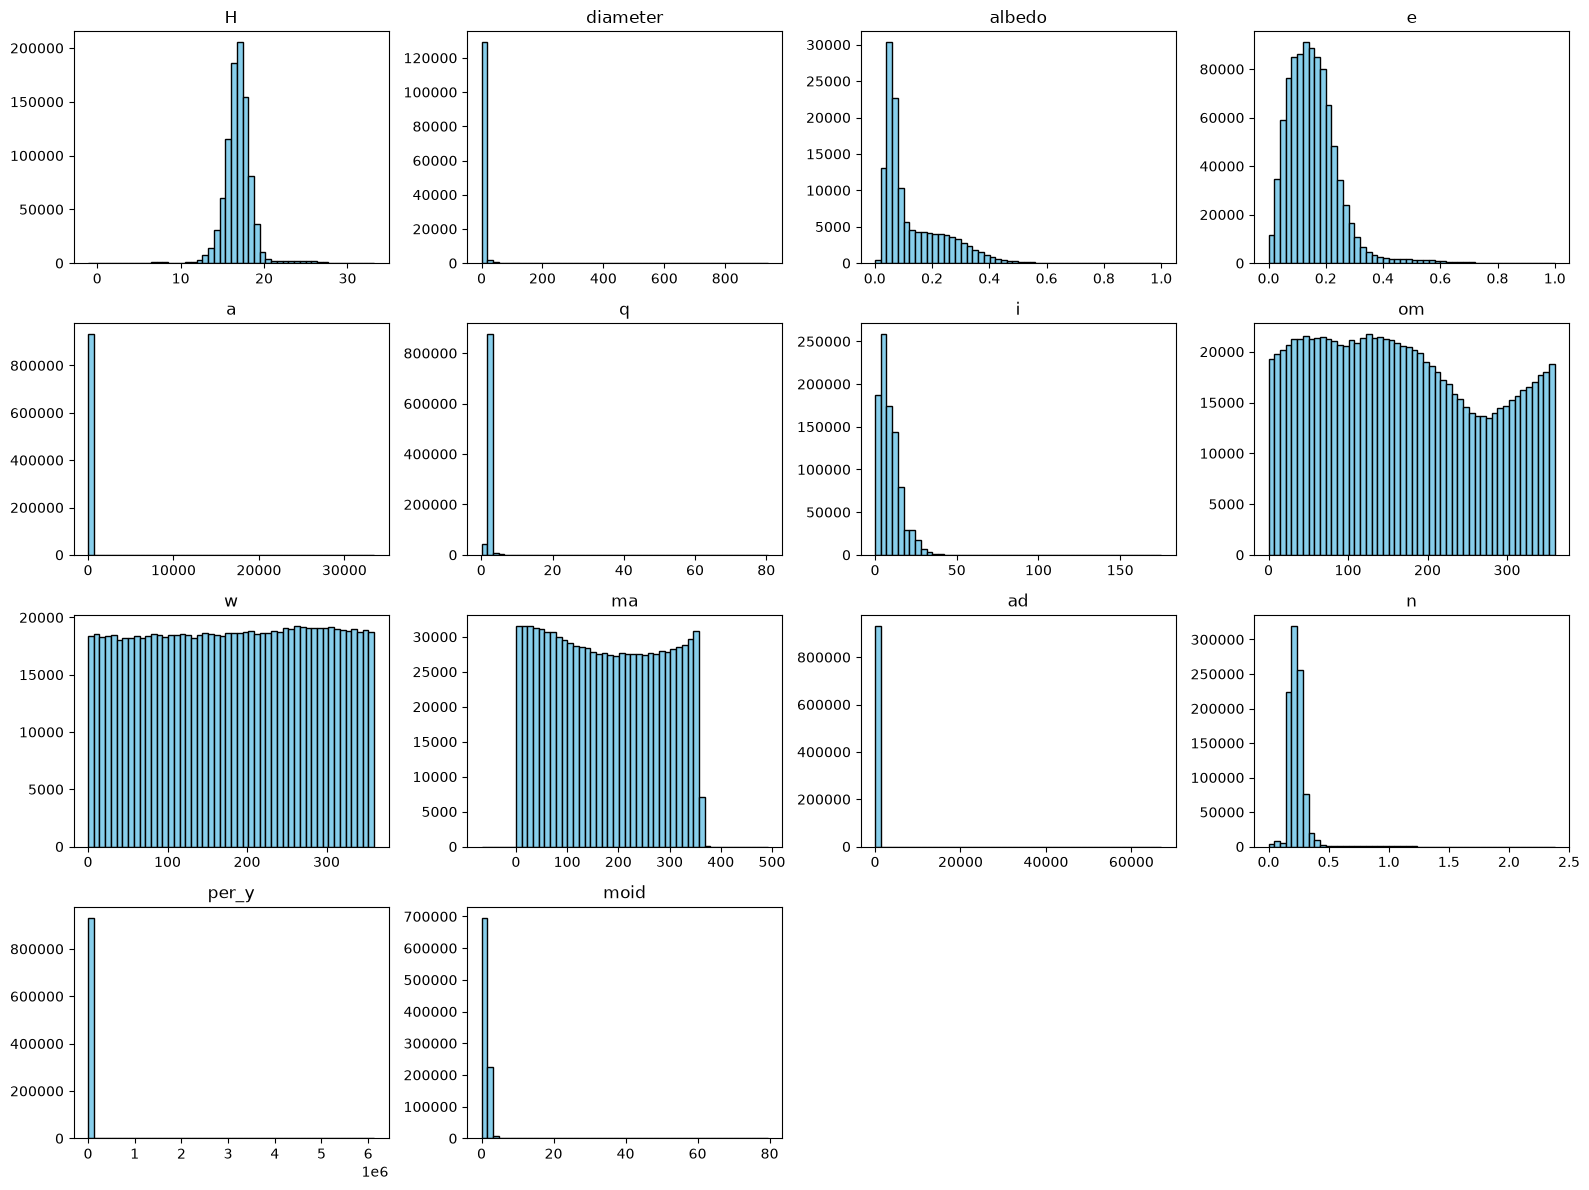

In [19]:
num_cols = ['H', 'diameter', 'albedo', 'e', 'a', 'q', 'i', 'om', 'w', 'ma',
            'ad', 'n', 'per_y', 'moid']

plt.figure(figsize=(16, 12))
for i in range(len(num_cols)):
    plt.subplot(4, 4, i + 1)
    plt.hist(data[num_cols[i]].dropna(), bins=50, color='skyblue', edgecolor='black')
    plt.title(num_cols[i])
plt.tight_layout()
plt.savefig('images/histograms.png')
plt.show()

Histograms show the shape of each column (normal, skewed, uniform) so we know which ones need transforming.

**Inference:**
- **H** is close to a bell shape, centred around 17 (most asteroids are a few km wide or smaller).
- **e** is right-skewed: most orbits are nearly circular (e 0.05 - 0.25); a small tail goes up to about 0.99 (NEOs and comet-like orbits).
- **i** is right-skewed: most asteroids orbit close to Earth's plane (below 20 degrees), a few go above 60.
- **a, q, ad, per_y, moid, diameter** show one tall bar and nothing else: a few extreme values (TNOs at thousands of AU, Ceres at 939 km) stretch the x-axis, so these columns need a log transform.
- **albedo** has two humps: dark asteroids (about 0.05) and bright ones (about 0.25), the well-known C-type and S-type groups.
- **om and w** are spread almost evenly from 0 to 360: orbit directions are random, so they are unlikely to predict hazard.
- **ma** has a few values below 0 and above 360; they are the same angle written differently (for example -10 = 350), not errors.

## Histograms with log scale for long-tail columns

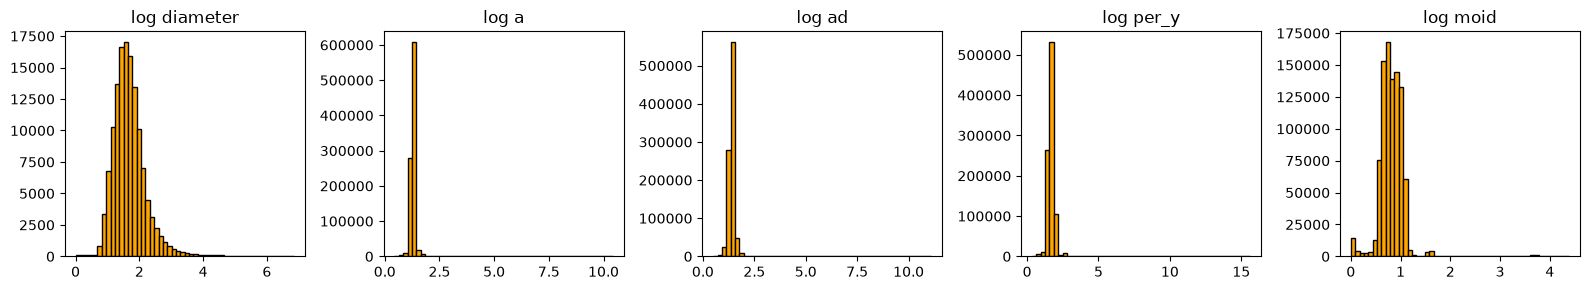

In [20]:
log_cols = ['diameter', 'a', 'ad', 'per_y', 'moid']

plt.figure(figsize=(16, 3))
for i in range(len(log_cols)):
    plt.subplot(1, 5, i + 1)
    plt.hist(np.log1p(data[log_cols[i]].dropna()), bins=50, color='orange', edgecolor='black')
    plt.title('log ' + log_cols[i])
plt.tight_layout()
plt.savefig('images/log_histograms.png')
plt.show()

Long-tail columns are unreadable on a normal scale; the log view shows their real shape.

**Inference:**
- After log, **diameter** becomes close to a bell shape (most asteroids are 2 - 10 km in this data).
- **moid** after log shows most asteroids far from Earth's orbit, with a small separate group near 0 (the near-Earth objects).
- **a, ad, per_y** are still narrow with a long right tail: most asteroids are in the main belt (about 2 - 3.3 AU), and the tail is the outer solar system.
- Conclusion: log makes the long-tail columns usable for models.

## Skewness of numeric columns

In [21]:
data[num_cols].skew().sort_values()

w           -0.02047
ma           0.04408
om           0.19832
H            0.62710
albedo       1.64768
e            1.90947
i            2.21490
n            5.65350
q           15.65513
moid        15.71322
diameter    25.56060
a          847.53535
ad         852.60532
per_y      939.89849
dtype: float64

Skewness gives a number to the shape, so we can decide which columns need a transform.

**Inference:**
- Skew between -0.5 and 0.5 = nearly symmetric: **w, ma, om** (angles).
- **H** (0.63) is only mildly skewed.
- **albedo, e, i** (1.6 - 2.2) are moderately skewed.
- **q, moid, diameter** (15 - 26) and **a, ad, per_y** (above 800) are extremely skewed and need a transform before modelling.

## Bar plots - pha, neo, class

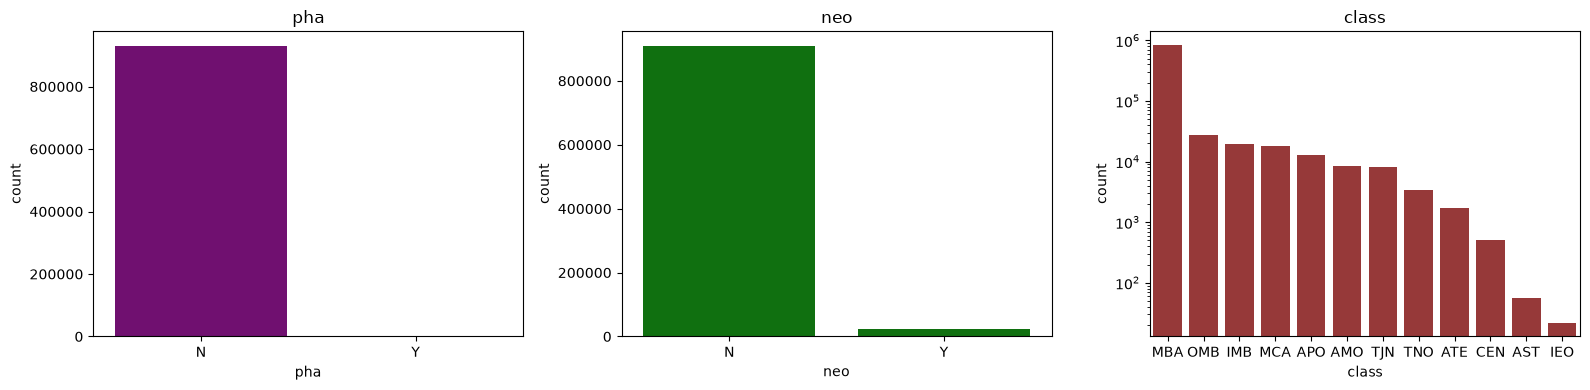

In [22]:
plt.figure(figsize=(16, 4))

plt.subplot(1, 3, 1)
sns.countplot(x=data['pha'], color='purple')
plt.title('pha')

plt.subplot(1, 3, 2)
sns.countplot(x=data['neo'], color='green')
plt.title('neo')

plt.subplot(1, 3, 3)
sns.countplot(x=data['class'], order=data['class'].value_counts().index, color='brown')
plt.title('class')
plt.yscale('log')

plt.tight_layout()
plt.savefig('images/countplots.png')
plt.show()

Bar charts show how many asteroids are in each category and how rare PHAs are.

**Inference:**
- **pha:** the Y bar is too small to see. PHAs are a tiny minority, so the classification model will need class-imbalance handling.
- **neo:** about 2.5% of asteroids are near-Earth objects.
- **class:** main belt asteroids (MBA) dominate (about 830,000). The y-axis is in log scale; without it, all other classes would be invisible. NEO classes (APO, AMO, ATE) are a few thousand each.

## Percentage of PHA

In [23]:
data['pha'].value_counts(normalize=True) * 100

pha
N   99.77841
Y    0.22159
Name: proportion, dtype: float64

Exact percentage of PHAs, which tells us how strong the class imbalance is.

**Inference:**
- Only **0.22%** of asteroids are PHAs (about 1 in 450).
- A model that always says "not PHA" would be 99.78% accurate and completely useless, so accuracy cannot be the main metric. Recall, precision and F1 must be used.

## Bivariate - features vs pha (box plots)

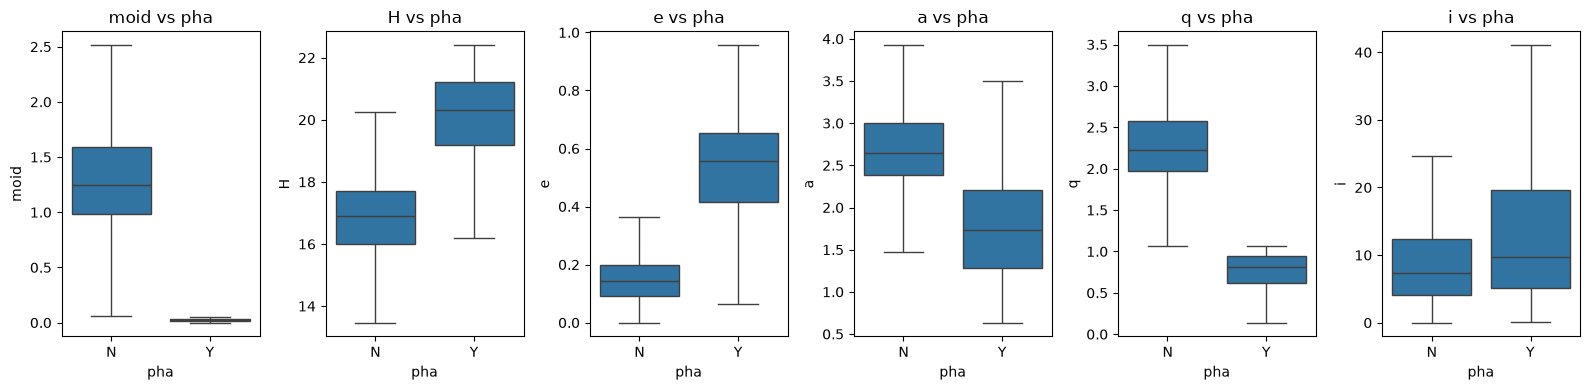

In [24]:
box_cols = ['moid', 'H', 'e', 'a', 'q', 'i']

plt.figure(figsize=(16, 4))
for i in range(len(box_cols)):
    plt.subplot(1, 6, i + 1)
    sns.boxplot(x=data['pha'], y=data[box_cols[i]], showfliers=False)
    plt.title(box_cols[i] + ' vs pha')
plt.tight_layout()
plt.savefig('images/boxplots_vs_pha.png')
plt.show()

Box plots compare each feature for PHA vs non-PHA, to find useful features and leakage.

**Inference:**
- **moid:** all PHAs sit below 0.05 AU while non-PHAs are spread up to about 2.5 AU. moid alone separates the classes perfectly, because pha is defined from moid. **This is data leakage** and moid must not be used to predict pha.
- **q:** PHAs have q below about 1.05 AU, non-PHAs mostly above 1.5 AU. q is almost the same information as moid, so it also leaks.
- **e:** PHAs have much higher eccentricity (median about 0.55 vs 0.15). A genuine and strong signal.
- **H:** PHAs have H between about 16 and 22 (the H <= 22 rule). Genuine signal.
- **a:** PHAs orbit closer to the Sun (median about 1.7 AU vs 2.65 AU). Genuine signal.
- **i:** PHAs have a slightly higher and wider inclination, but the boxes overlap a lot. Weak signal.

## moid vs H coloured by pha (PHA rule: moid <= 0.05 and H <= 22)

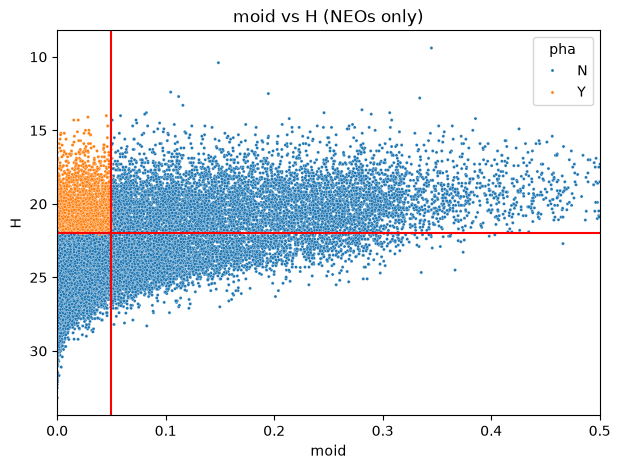

In [25]:
neo_data = data[data['neo'] == 'Y']

plt.figure(figsize=(7, 5))
sns.scatterplot(x=neo_data['moid'], y=neo_data['H'], hue=neo_data['pha'], s=5)
plt.axvline(0.05, color='red')
plt.axhline(22, color='red')
plt.xlim(0, 0.5)
plt.gca().invert_yaxis()
plt.title('moid vs H (NEOs only)')
plt.savefig('images/moid_vs_H.png')
plt.show()

Check the official PHA rule (moid <= 0.05 and H <= 22) visually on the near-Earth objects.

**Inference:**
- Every orange (PHA) point is inside the top-left box made by the red lines: **moid <= 0.05 AU and H <= 22**.
- This confirms the official PHA rule exactly. With moid and H, the target can be calculated without any ML.
- Many NEOs have small moid but H > 22 (too small to count as hazardous), and many are bright but far (moid > 0.05).

## H vs diameter

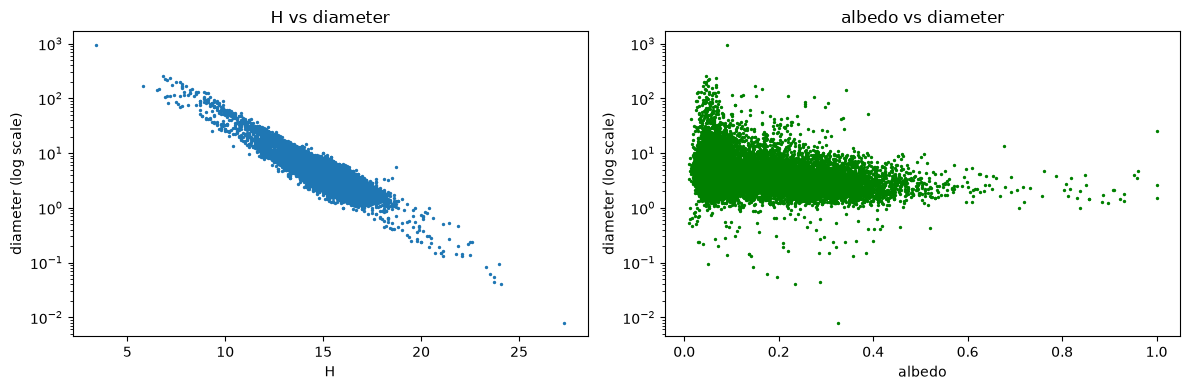

In [26]:
sample = data.dropna(subset=['diameter']).sample(20000, random_state=42)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.scatter(sample['H'], sample['diameter'], s=2)
plt.yscale('log')
plt.xlabel('H')
plt.ylabel('diameter (log scale)')
plt.title('H vs diameter')

plt.subplot(1, 2, 2)
plt.scatter(sample['albedo'], sample['diameter'], s=2, color='green')
plt.yscale('log')
plt.xlabel('albedo')
plt.ylabel('diameter (log scale)')
plt.title('albedo vs diameter')

plt.tight_layout()
plt.savefig('images/H_albedo_vs_diameter.png')
plt.show()

See how brightness (H) and reflectivity (albedo) relate to size, to choose features for the diameter model.

**Inference:**
- **H vs diameter:** a tight straight line on the log scale. Lower H (brighter) = bigger asteroid. H is the strongest predictor of diameter.
- **albedo vs diameter:** a wide cloud with no clear line on its own, but darker asteroids (low albedo) reach bigger sizes.
- Together they match the physics formula D = 1329 / sqrt(albedo) x 10^(-H/5). After taking log, log(D) is a straight-line function of H and log(albedo). So H + albedo should predict diameter very well.

## a vs e and a vs i coloured by class

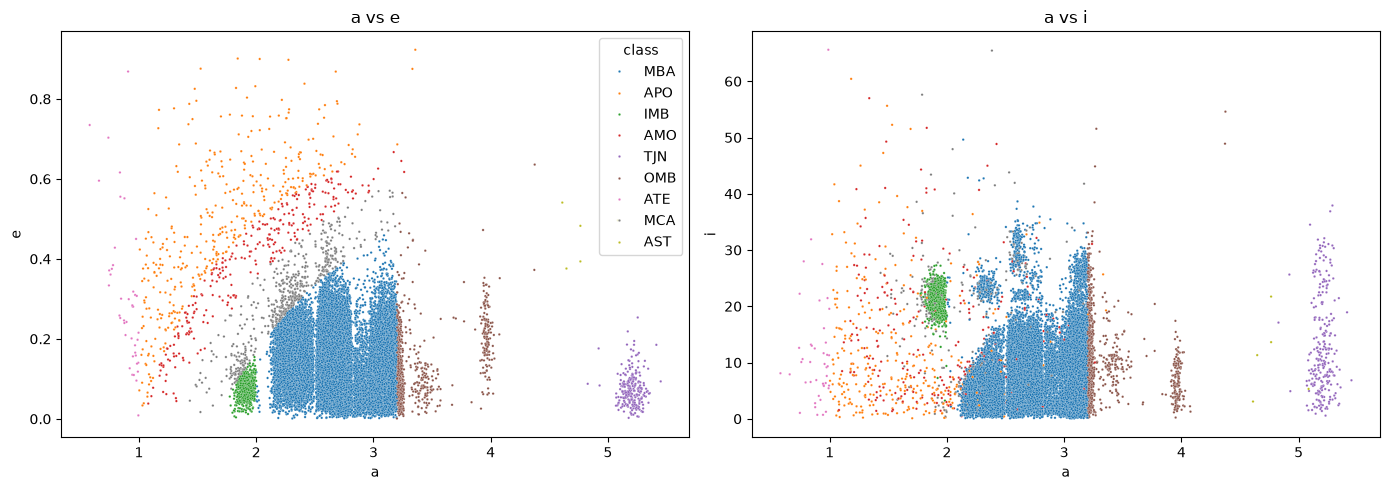

In [27]:
sample = data.sample(30000, random_state=42)
sample = sample[sample['a'] < 6]

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
sns.scatterplot(x=sample['a'], y=sample['e'], hue=sample['class'], s=3)
plt.title('a vs e')

plt.subplot(1, 2, 2)
sns.scatterplot(x=sample['a'], y=sample['i'], hue=sample['class'], s=3, legend=False)
plt.title('a vs i')

plt.tight_layout()
plt.savefig('images/a_e_i_by_class.png')
plt.show()

See whether orbital classes form natural regions, which tells us clustering should work.

**Inference:**
- Classes form clear regions in orbit space:
  - **MBA** (blue) fills a = 2.1 - 3.3 AU with low e.
  - **APO, AMO, ATE** (NEOs) sit at small a and high e.
  - **TJN** (Jupiter Trojans) is a separate group at a of about 5.2 AU.
  - **IMB** (green) is a tight group at a of about 1.9 AU with high i (about 20 degrees).
- The main belt has empty vertical gaps (at about 2.5 and 2.8 AU). These are the **Kirkwood gaps**, cleared by Jupiter's gravity.
- Because the groups are natural regions, clustering on a, e and i should find them without labels.

## Correlation heatmap

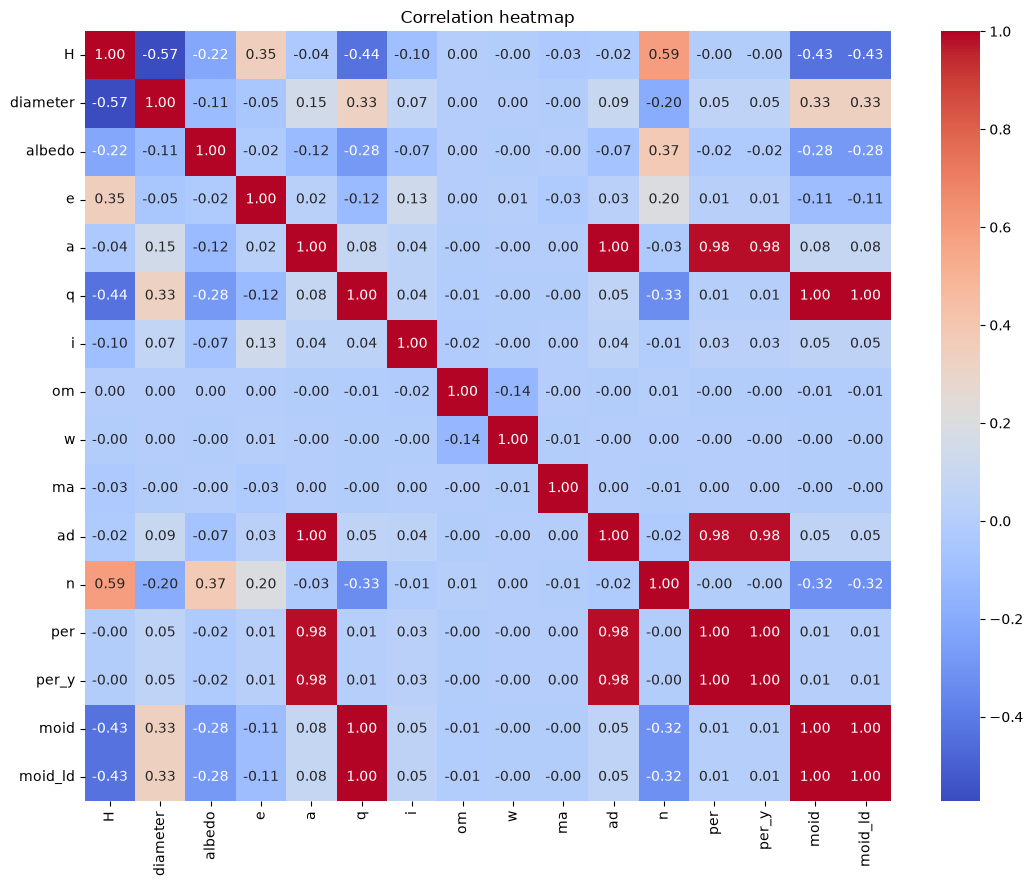

In [28]:
corr_cols = ['H', 'diameter', 'albedo', 'e', 'a', 'q', 'i', 'om', 'w', 'ma',
             'ad', 'n', 'per', 'per_y', 'moid', 'moid_ld']

plt.figure(figsize=(13, 10))
sns.heatmap(data[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation heatmap')
plt.savefig('images/correlation_heatmap.png')
plt.show()

Find columns that carry the same information (multicollinearity) and columns that leak the target.

**Inference:**
- **moid and moid_ld = 1.00:** the same value in different units (AU vs lunar distance). Keep only one.
- **q and moid = 1.00:** almost the same information. Both leak the pha answer.
- **a, ad, per, per_y = 0.98 - 1.00:** all calculated from a (Kepler's law). Keep only a for prediction.
- **H and diameter = -0.57:** a strong negative relation (brighter = bigger). It looks weaker here only because diameter is not yet log transformed.
- **om, w, ma are about 0 with everything:** orbit angles carry almost no linear information.
- Conclusion: several columns are duplicates (multicollinearity) and must be removed in feature selection.

## Outlier count using IQR

In [29]:
outlier_count = {}
for col in num_cols:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outlier_count[col] = len(data[(data[col] < lower) | (data[col] > upper)])

pd.Series(outlier_count).sort_values(ascending=False)

H           39672
i           29294
ad          29275
q           29248
e           24603
a           24555
moid        24554
n           23954
per_y       21786
diameter     9424
albedo       2972
ma              0
om              0
w               0
dtype: int64

Count extreme values in each column with the IQR rule before deciding what to do with them.

**Inference:**
- H and the orbital columns have about 20,000 - 40,000 IQR outliers each (2 - 4% of rows).
- diameter (9,424) and albedo (2,972) have fewer because about 86% of their values are empty.
- The angles (om, w, ma) have 0 outliers because they are spread evenly from 0 to 360.
- The next cell checks what these outliers are, to decide whether to remove them.

## Which classes are the outliers in a? (they are real objects like TNOs and comets-like orbits)

In [30]:
Q1 = data['a'].quantile(0.25)
Q3 = data['a'].quantile(0.75)
upper = Q3 + 1.5 * (Q3 - Q1)
data[data['a'] > upper]['class'].value_counts()

class
TJN    8122
OMB    4231
TNO    3460
CEN     503
AST      57
AMO      14
APO       7
Name: count, dtype: int64

Check which asteroids are the outliers, to decide if they are errors or real objects.

**Inference:**
- The "outliers" in a are Jupiter Trojans (TJN), outer main belt (OMB), trans-Neptunian objects (TNO) and Centaurs (CEN).
- These are **real astronomical objects**, not data errors. Removing them would delete whole populations.
- Decision: **keep the outliers** and reduce their effect with a log transform and tree-based models.

## Save the cleaned data

In [31]:
data.to_csv('cleaned_data.csv', index=False)
data.shape

(932336, 19)

Save the cleaned table so the next notebook starts from clean data.